Shahlo Solieva

Updated 10/14/2026

**Figure 2A** Comparing Fab (with constant region) vs Fv (only variable region) simulations

In [3]:
# import all necessary packages
import numpy as np
import matplotlib.pyplot as plt
import pickle
import mdtraj as md 

FAST_BASE_PATH = "/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/RMSF"
FAH_BASE_PATH =  "/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/RMSF"
CLUSTER_BASE = "/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/clustering/radius_15_variable/data"
fig_base_path=f'../figures/manuscript'

# Helper functions

In [2]:
def load_and_split_rmsf(BASE_PATH, system_name, vh_end):
    """
    Load rmsf for given system, split into hc and lc data. 
    """
    DATA_PATH = f"{BASE_PATH}/data/apo/{system_name}/VHC_VLC_CA_RMSF.npy"
    rmsf = np.load(DATA_PATH, allow_pickle=True)*10 

    hc = rmsf[:vh_end]
    lc = rmsf[vh_end:]
    return hc, lc

def calculate_95CI_and_split(BASE_PATH, system_name, vh_end):
    """
    Load bootstrapped (n=1000) rmsf for given system, split into hc and lc data. 
    """
    DATA_PATH = f"{BASE_PATH}/data/apo/{system_name}/n1000_bootstraps_VHC_VLC_CA_RMSF_avgs.npy"
    rmsfs_all_average = np.load(DATA_PATH)*10
    ci_low  = np.percentile(rmsfs_all_average, 2.5,  axis=0) 
    ci_high = np.percentile(rmsfs_all_average, 97.5, axis=0)  
    ci_hc   = [ci_low[:vh_end], ci_high[:vh_end]]  # ci low for HC, ci high for HC
    ci_lc   = [ci_low[vh_end:], ci_high[vh_end:]] 
    return ci_hc, ci_lc 

def get_bar_info(basepath, Ab_ranges, CI=None):
    if CI:
        hc_rmsf, lc_rmsf =    load_and_split_rmsf(basepath, Ab_ranges[0], Ab_ranges[2])
        hc_ci,   lc_ci = calculate_95CI_and_split(basepath, Ab_ranges[0], Ab_ranges[2])
        return [hc_rmsf, lc_rmsf, hc_ci,   lc_ci]
    else: 
        hc_rmsf, lc_rmsf =    load_and_split_rmsf(basepath, Ab_ranges[0], Ab_ranges[2])
        return [hc_rmsf, lc_rmsf]

# plot



CH103_naive 	 [1.2653111855973416, 1.391146348402127] [1.8772906769570281, 1.8188747834592405]
CH103_I32 	 [0.7091593979667686, 0.85407704700437] [1.0682457183872136, 1.1519343463644238]
CH103_I2 	 [0.8239294981597292, 0.8522132474741287] [1.206141826220628, 1.1033061503909845]
CH103_mature 	 [0.6992821100524612, 0.7078912757088041] [0.9806181262811259, 0.78573959017424]


CH65_naive 	 [0.9396136945185986, 0.9748848393440078] [1.2774054599873732, 1.3515446281416506]
CH65_I2 	 [0.7913539250468717, 0.7952471705913507] [1.2389941556724664, 1.0392073419115635]
CH65_mature 	 [0.7563485772029376, 0.858623690580813] [1.0137152339956677, 1.2463580369492415]


CAP256_naive 	 [1.8573843360867128, 2.303071788506173] [2.536965856431522, 3.283816735886158]
CAP256_I01 	 [1.669246840852373, 1.9824247622968962] [2.33341339421518, 2.576150873422291]
CAP256_I03 	 [1.4438998962326772, 1.4569800116452072] [1.7829287887142344, 1.7923326298481415]
CAP256_I04 	 [1.9284654793338185, 1.9014552839698597] [2.8

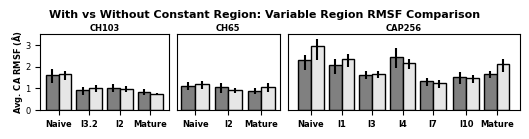

In [4]:
Ab_ranges_list_FAST=[[("CH103_naive_VC",  1, 121, 1, 108), ("CH103_I32_VC", 1, 121, 2, 108),    ("CH103_I2_VC", 1, 121, 1, 108), ("CH103_mature_VC", 1, 121, 1, 105)],
                    [("CH65_naive_VC",   1, 126, 1, 108), ("CH65_I2_VC",   1, 126, 1, 108), ("CH65_mature_VC",  1, 126, 1, 108)],
                    [("CAP256_naive_VC",1, 144, 1, 111),  ("CAP256_I01_VC",1, 144, 1, 111), ("CAP256_I03_VC",1, 144, 1, 111), ("CAP256_I04_VC",1, 144, 1, 111),("CAP256_I07_VC",1, 111, 1, 144), ("CAP256_I10_VC",1, 111, 1, 144), ("CAP256_mature_VC", 1, 145, 1, 111)]] 

Ab_ranges_list_fv = [[("CH103_naive_V",  1, 121, 1, 108), ("CH103_I32_V", 1, 121, 2, 108),    ("CH103_I2_V", 1, 121, 1, 108), ("CH103_mature_V", 1, 121, 1, 105)],
                    [("CH65_naive_V",   1, 126, 1, 108),  ("CH65_I2_V",   1, 126, 1, 108), ("CH65_mature_V",  1, 126, 1, 108)],
                    [("CAP256_naive_V", 1, 144, 1, 111),  ("CAP256_I01_V",1, 144, 1, 111),  ("CAP256_I03_V",1, 144, 1, 111),("CAP256_I04_V",1, 144, 1, 111),("CAP256_I07_V",1, 144, 1, 111), ("CAP256_I10_V",1, 144, 1, 111), ("CAP256_mature_V", 1, 145, 1, 111)]] 

Ab_ranges_list_names = [['Naive', 'I3.2', 'I2', 'Mature'],
                        ['Naive','I2','Mature'],
                        ['Naive','I1','I3','I4','I7','I10','Mature']]
fig, axes = plt.subplots(1, 3, figsize=(5.4, 1.6), sharey=True, gridspec_kw={'width_ratios': [1, 0.8, 1.8]})

x_options  = [[0.2,1.2], [2.6,3.6], [5.0,6.0], [7.4,8.4], [9.8,10.8], [12.4,13.4], [14.8,15.8]]

x_options_ = [[0.7,3.1,5.5,7.9], 
              [0.7,3.1,5.5],
              [0.7,3.1,5.5,7.9,10.3,12.9,15.3]]

labels=['CH103','CH65','CAP256']
for i in range(len(Ab_ranges_list_fv)):
    print('\n')
    for j in range(len(Ab_ranges_list_fv[i])):
        hc_rmsf, lc_rmsf, hc_ci, lc_ci            = get_bar_info(FAST_BASE_PATH, Ab_ranges_list_FAST[i][j], CI=True)
        hc_rmsf_fv, lc_rmsf_fv, hc_ci_fv,lc_ci_fv = get_bar_info(FAST_BASE_PATH, Ab_ranges_list_fv[i][j],   CI=True)
        low_ci =  [np.average(np.concatenate([hc_ci[0],lc_ci[0]])),
                   np.average(np.concatenate([hc_ci_fv[0],lc_ci_fv[0]]))]
        high_ci = [np.average(np.concatenate([hc_ci[1],lc_ci[1]])),
                   np.average(np.concatenate([hc_ci_fv[1],lc_ci_fv[1]]))]
        avg_data = [np.average(np.concatenate([hc_rmsf,lc_rmsf])), np.average(np.concatenate([hc_rmsf_fv,lc_rmsf_fv]))]
        errs = [[avg_data[0]-low_ci[0], high_ci[0]-avg_data[0]], 
                [avg_data[1]-low_ci[1], high_ci[1]-avg_data[1]]]
        print(Ab_ranges_list_fv[i][j][0][:-2], '\t', low_ci,high_ci)
        axes[i].bar(x_options[j],avg_data, yerr=np.array(errs).T, width=1, edgecolor='k', color=['0.5','0.9'])

    axes[i].set_title(f'{labels[i]}', fontsize=6, weight='bold', pad=2)
    axes[i].set_xticks(x_options_[i])
    axes[i].set_xticklabels(Ab_ranges_list_names[i], fontsize=6, weight='bold')

axes[0].set_ylabel('Avg. CA RMSF ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
axes[0].set_yticks([0,1,2,3])
axes[0].set_yticklabels([0,1,2,3], fontsize=6)
plt.ylim(0,3.5)
for i in range(1,3):
    axes[i].yaxis.set_visible(False)
fig.suptitle('With vs Without Constant Region: Variable Region RMSF Comparison', fontsize=8, y=0.84, weight='bold')
#axes[0].legend(['Fab','Fv'], color=['0.5','0.9'])
plt.tight_layout()
plt.subplots_adjust(wspace=0.05)

plt.savefig(f"{fig_base_path}/Fig2A_Fab_v_Fv_RMSF_per_region_Naive_Mature.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

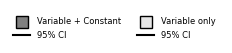

In [5]:
# legend: 
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

plt.figure(figsize=[1,0.4])
plt.axis('off')

point = Line2D([0], [0], markerfacecolor='0.5', label='Variable + Constant' , marker='s', markersize=8, 
         markeredgecolor='k',  linestyle='')
line = Line2D([0], [0], label='95% CI', color='k')

#patch2 = mpatches.Patch(color='0.9', label='FAH', markerfacecolor='k')   
point2 = Line2D([0], [0], markerfacecolor='0.9', label='Variable only' , marker='s', markersize=8, 
         markeredgecolor='k',  linestyle='')
line2 = Line2D([0], [0], label='95% CI', color='k')

plt.legend(handles=[point, line, point2, line2], frameon=False, fontsize=6, ncol=2)
plt.savefig(f"{fig_base_path}/Fig2A_Fab_v_Fv_RMSF_per_region_Naive_Mature_legend.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()
